# Custom GRN Topology Generation and Graph-Tool Inference

This notebook allows you to generate custom Gene Regulatory Networks (GRNs) using a directed Scale-Free topology, simulate their trajectories with heterogeneous kinetics, and perform Bayesian inference using the `gene_expr` extension for `graph-tool`.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# Ensure project root is in path to load gene_expr
if os.path.abspath('.') not in sys.path:
    sys.path.insert(0, os.path.abspath('.'))

import graph_tool.all as gt
from gene_expr import GeneExprBlockState

In [2]:
def sigmoid(x):
    x = np.clip(x, -50, 50)
    return 1.0 / (1.0 + np.exp(-x))

In [3]:
def generate_scale_free_W(N, m=2, seed=42):
    """Generates a scale-free directed GRN using directed preferential attachment."""
    np.random.seed(seed)
    W = np.zeros((N, N))
    out_degrees = np.zeros(N)
    
    core_size = m + 1
    for i in range(core_size):
        for j in range(core_size):
            if i != j and np.random.rand() > 0.5:
                sign = np.random.choice([-1, 1])
                mag = np.random.uniform(1.0, 3.0)
                W[i, j] = sign * mag
                out_degrees[j] += 1
                
    for i in range(core_size, N):
        weights = out_degrees[:i] + 1.0
        probs = weights / np.sum(weights)
        regulators = np.random.choice(i, size=m, replace=False, p=probs)
        
        for reg in regulators:
            sign = np.random.choice([-1, 1])
            mag = np.random.uniform(1.0, 3.0)
            W[i, reg] = sign * mag
            out_degrees[reg] += 1
            
    return W

In [4]:
def simulate_realistic_pairs(W, M=200, dt_sim=0.01, dt_sample=0.5, dt_meas=0.05, D_base=0.1, mean_d=0.5, std_d=0.5, mean_V=2.0, std_V=0.5, seed=123, t_window=(0.0, 3.0)):
    N = W.shape[0]
    np.random.seed(seed)
    
    # Heterogeneous parameters
    d = np.ones(N) * mean_d  # Homogeneous parameters
    V = np.ones(N) * mean_V  # Homogeneous parameters
    
    t_start, t_end = t_window
    sample_times = np.arange(t_start, t_end + 1e-9, dt_sample)
    if len(sample_times) == 0:
        sample_times = np.array([t_start])
    K = len(sample_times)
    
    n_trajectories = int(np.ceil(M / K))
    
    T_max = t_end + dt_meas
    n_steps = int(np.round(T_max / dt_sim))
    
    sample_step_indices = [int(np.round(t / dt_sim)) for t in sample_times]
    next_step_indices = [int(np.round((t + dt_meas) / dt_sim)) for t in sample_times]
    
    all_pairs = []
    
    for traj_idx in range(n_trajectories):
        x = np.random.uniform(0.1, 1.0, size=N).astype(np.float64)
        history = {0: x.copy()}
        
        for step in range(1, n_steps + 1):
            drift = -d * x + V * sigmoid(np.dot(W, x))
            noise = np.sqrt(D_base * np.maximum(x, 0.01)) * np.random.normal(0, np.sqrt(dt_sim), size=N)
            x = np.maximum(x + dt_sim * drift + noise, 0.01)
            
            if step in sample_step_indices or step in next_step_indices:
                history[step] = x.copy()
                
        for s_idx, n_idx in zip(sample_step_indices, next_step_indices):
            pair = np.column_stack([history[s_idx], history[n_idx]])
            all_pairs.append(pair)
            if len(all_pairs) == M:
                break
        if len(all_pairs) == M:
            break
            
    out_degrees = (W != 0).sum(axis=0)
    hub_node = np.argmax(out_degrees)
            
    return all_pairs, hub_node, out_degrees, d, V


### Custom Parameters & Trajectory Simulation
Set the parameters and generate the network and trajectories.

In [30]:
# Network Parameters
N = 50              # Number of genes
m = 1               # Edges to attach from a new node to existing nodes
seed_network = 42   # Random seed for network generation

# Simulation Parameters
M_pairs = 500      # Number of observation pairs to harvest
dt_sim = 0.01      # Simulation integration step
dt_meas = 0.05     # Measurement interval for the pair
dt_sample = 0.5    # Interval between harvested pairs in the same trajectory
t_window = (0.0, 3.0) # ONLY TRANSIENT REGION
D_base = 0.02       # Base multiplicative noise level (decreased for better signal)

# Kinetic Parameters (Mean and Std of Log-Normal distribution)
mean_d = 0.5    # Average decay rate
std_d = 0.0     # Heterogeneity in decay rate (DISABLED)
mean_V = 2.0        # Average max transcription rate
std_V = 0.0         # Heterogeneity in transcription rate (DISABLED)
seed_sim = 123      # Random seed for simulation

# Generate Network
W_true = generate_scale_free_W(N, m, seed=seed_network)

# Simulate Trajectories
pairs, hub_node, out_degrees, d_true, V_true = simulate_realistic_pairs(
    W_true, M=M_pairs, dt_sim=dt_sim, dt_sample=dt_sample, dt_meas=dt_meas, 
    D_base=D_base, mean_d=mean_d, std_d=std_d, mean_V=mean_V, std_V=std_V, 
    seed=seed_sim, t_window=t_window
)

# Format for graph-tool inference (list of N x 2 arrays)
s = pairs
print(f"Master Regulator is Node {hub_node} with {out_degrees[hub_node]} outgoing edges.")
print(f"Harvested {len(s)} state-transition pairs from transient windows {t_window}.")


Master Regulator is Node 0 with 24 outgoing edges.
Harvested 500 state-transition pairs from transient windows (0.0, 3.0).


In [24]:
# Plot the first example trajectory




### Graph-Tool Bayesian Inference
We now use the `GeneExprBlockState` from the graph-tool extension to infer the network topology from the time-series data.
First, we evaluate the description length (entropy) of the true data-generating configuration to establish a baseline.

In [31]:
# Construct the true graph structure and weights in graph-tool format
g_true = gt.Graph(directed=True)
g_true.add_vertex(N)
ep_x = g_true.new_edge_property("double")

for i in range(N):
    for j in range(N):
        if W_true[i, j] != 0:
            # j is the source regulator, i is the target regulated gene
            e = g_true.add_edge(j, i)
            ep_x[e] = W_true[i, j]
g_true.ep["x"] = ep_x

# Average True node parameters (the inference extension infers global effective parameters)
theta_true = [np.log(np.mean(d_true)), np.log(np.mean(V_true)), np.log(D_base)]

# FIX: Explicitly pass x=g_true.ep["x"] so the edge weights are correctly registered!
state_true = GeneExprBlockState(s, dt=dt_meas, g=g_true, theta=theta_true, x=g_true.ep["x"])
S_true = state_true.entropy()
print(f"Entropy of the TRUE network and parameters: {S_true:.4f}")

Entropy of the TRUE network and parameters: -48403.1314


In [32]:
import scipy.optimize as opt
import numpy as np

def optimize_global_theta(state):
    S_cur = state.entropy()
    theta_cur = state.theta.get_2d_array([0, 1, 2])[:, 0]
    
    def objective(theta_val):
        arr = state.theta.get_2d_array([0, 1, 2])
        arr[0, :] = theta_val[0]
        arr[1, :] = theta_val[1]
        arr[2, :] = theta_val[2]
        state.theta.set_2d_array(arr)
        return state.entropy()
    
    res = opt.minimize(objective, theta_cur, method='Nelder-Mead', options={'maxiter': 30})
    
    if res.fun < S_cur:
        arr = state.theta.get_2d_array([0, 1, 2])
        arr[0, :] = res.x[0]
        arr[1, :] = res.x[1]
        arr[2, :] = res.x[2]
        state.theta.set_2d_array(arr)
        return S_cur - res.fun
    else:
        arr = state.theta.get_2d_array([0, 1, 2])
        arr[0, :] = theta_cur[0]
        arr[1, :] = theta_cur[1]
        arr[2, :] = theta_cur[2]
        state.theta.set_2d_array(arr)
        return 0.0

# CONFIGURATION OPTION
OPTIMIZE_GLOBAL_PARAMS = True

print("\nInstantiating GeneExprBlockState from scratch (empty network)...")
g_init = g_true.copy()

if OPTIMIZE_GLOBAL_PARAMS:
    # We will use 0.05 for D_base (np.log(0.05) ~ -3.0) to avoid the zero-edge trap,
    # and 0.0 for d and V. This is an uninformative but safe start.
    initial_theta = [0.0, 0.0, np.log(0.05)]
else:
    initial_theta = [np.log(mean_d), np.log(mean_V), np.log(D_base)]

state = GeneExprBlockState(s, dt=dt_meas, state_args=dict(deg_corr=True), theta=initial_theta)
S_init = state.entropy()
print(f"Initial description length (empty network): {S_init:.4f}")

# --- PHASE 1: Equilibration (Burn-in) ---
n_burnin = 50
print(f"\n--- PHASE 1: Equilibration ({n_burnin} sweeps) ---")
for sweep in range(1, n_burnin + 1):
    dS_topo, nmoves = state.mcmc_sweep(niter=10, theta=0)
    dS_param = optimize_global_theta(state) if OPTIMIZE_GLOBAL_PARAMS else 0.0
    if sweep % 10 == 0 or sweep == 1:
        print(f"Burn-in Sweep {sweep:2d}/{n_burnin}: Entropy = {state.entropy():8.4f} (dS_topo = {dS_topo:8.4f}, dS_param = {-dS_param:8.4f}, moves = {nmoves:4d})")

# --- PHASE 2: Posterior Sampling ---
n_samples = 100
delta_k = 1 # Sample every sweep
print(f"\n--- PHASE 2: Posterior Sampling ({n_samples} samples, every {delta_k} sweeps) ---")

W_ensemble = []
theta_ensemble = []

for sample_idx in range(1, n_samples + 1):
    for _ in range(delta_k):
        dS_topo, nmoves = state.mcmc_sweep(niter=10, theta=0)
        dS_param = optimize_global_theta(state) if OPTIMIZE_GLOBAL_PARAMS else 0.0
        
    S_cur = state.entropy()
    
    # Extract the adjacency matrix (weights)
    g_curr = state.get_graph()
    W_curr = np.zeros((N, N))
    x_prop = state.x
    for e in g_curr.edges():
        W_curr[int(e.target()), int(e.source())] = x_prop[e]
    W_ensemble.append(W_curr)
    
    # Extract global parameters
    theta_curr = state.theta.get_2d_array([0, 1, 2])[:, 0]
    theta_ensemble.append(theta_curr)
    
    if sample_idx % 10 == 0 or sample_idx == 1:
        print(f"Sample {sample_idx:3d}/{n_samples}: Entropy = {S_cur:8.4f}")

W_ensemble = np.array(W_ensemble)
theta_ensemble = np.array(theta_ensemble)

# Calculate Edge Probabilities and Weight distributions
# W_ensemble shape: (N_samples, N, N)
edge_exists = (W_ensemble != 0).astype(float)
edge_probabilities = np.mean(edge_exists, axis=0)

# Mask for calculating mean/std only when edge exists
masked_W = np.ma.masked_equal(W_ensemble, 0)
weight_mean = masked_W.mean(axis=0).filled(0.0)
weight_std = masked_W.std(axis=0).filled(0.0)

# Save to disk
save_path = "grn_ensemble_results.npz"
np.savez_compressed(
    save_path, 
    W_ensemble=W_ensemble, 
    theta_ensemble=theta_ensemble,
    edge_probabilities=edge_probabilities,
    weight_mean=weight_mean,
    weight_std=weight_std
)
print(f"\nEnsemble results saved to {save_path}!")



Instantiating GeneExprBlockState from scratch (empty network)...
Initial description length (empty network): -12260.6966

Running MCMC Sweeps (Network Structure + Optimized Global Parameters)...
Sweep  1/30: Entropy = -25479.9459 (dS_topo =   0.0000, dS_param = -13219.2493, moves = 51632)
Sweep  5/30: Entropy = -47061.8427 (dS_topo = -105.7203, dS_param =  -5.6839, moves = 26829)
Sweep 10/30: Entropy = -47376.9186 (dS_topo = -52.7841, dS_param =  -0.9544, moves = 31176)
Sweep 15/30: Entropy = -47415.2933 (dS_topo = -72.7365, dS_param =  -0.7894, moves = 30074)
Sweep 20/30: Entropy = -47486.0629 (dS_topo = -47.0614, dS_param =  -1.8763, moves = 27047)
Sweep 25/30: Entropy = -47441.5152 (dS_topo = -14.0780, dS_param =  -1.6910, moves = 27364)
Sweep 30/30: Entropy = -47608.1670 (dS_topo = -61.7951, dS_param =  -1.1492, moves = 29119)


### Evaluation and Visualization
Compare the inferred network with the ground truth topology both quantitatively and visually.

In [33]:
def compute_reconstruction_metrics(W_true, W_inferred):
    N = W_true.shape[0]
    mask = ~np.eye(N, dtype=bool)  # ignore diagonal
    
    gt_edges = (W_true[mask] != 0).astype(int)
    inf_edges = (W_inferred[mask] != 0).astype(int)
    
    tp = np.sum((gt_edges == 1) & (inf_edges == 1))
    fp = np.sum((gt_edges == 0) & (inf_edges == 1))
    fn = np.sum((gt_edges == 1) & (inf_edges == 0))
    tn = np.sum((gt_edges == 0) & (inf_edges == 0))
    
    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1 = 2 * precision * tpr / (precision + tpr) if (precision + tpr) > 0 else 0.0
    shd = fp + fn
    
    return {
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "TPR (Recall)": tpr, "FPR": fpr,
        "Precision": precision, "F1-Score": f1,
        "SHD": shd
    }

W_inferred = np.zeros((N, N), dtype=float)
try:
    weight_ep = state.x
except AttributeError:
    ep_keys = list(best_graph.ep.keys())
    weight_ep = best_graph.ep[ep_keys[0]] if ep_keys else None

for e in best_graph.edges():
    src, tgt = int(e.source()), int(e.target())
    if src != tgt:
        w = 1.0
        if weight_ep is not None:
            val = weight_ep[e]
            if hasattr(val, '__iter__') and not isinstance(val, str):
                w = float(val[0])
            else:
                w = float(val)
        W_inferred[tgt, src] = w

metrics = compute_reconstruction_metrics(W_true, W_inferred)
print("Reconstruction Metrics vs Ground Truth:")
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"  {k}: {v:.3f}")
    else:
        print(f"  {k}: {v}")

Reconstruction Metrics vs Ground Truth:
  TP: 31
  FP: 142
  FN: 18
  TN: 2259
  TPR (Recall): 0.633
  FPR: 0.059
  Precision: 0.179
  F1-Score: 0.279
  SHD: 160


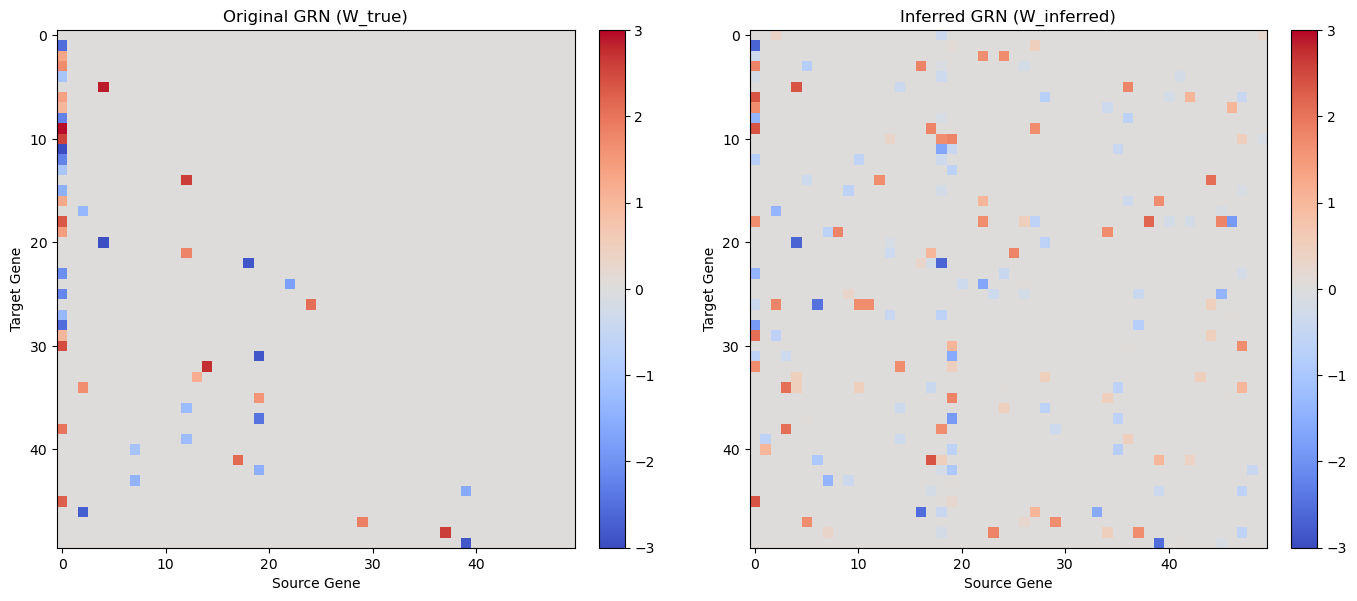

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Original Matrix
im1 = axes[0].imshow(W_true, cmap='coolwarm', vmin=-3, vmax=3)
axes[0].set_title("Original GRN (W_true)")
axes[0].set_xlabel("Source Gene")
axes[0].set_ylabel("Target Gene")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Inferred Matrix
im2 = axes[1].imshow(W_inferred, cmap='coolwarm', vmin=-3, vmax=3)
axes[1].set_title("Inferred GRN (W_inferred)")
axes[1].set_xlabel("Source Gene")
axes[1].set_ylabel("Target Gene")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

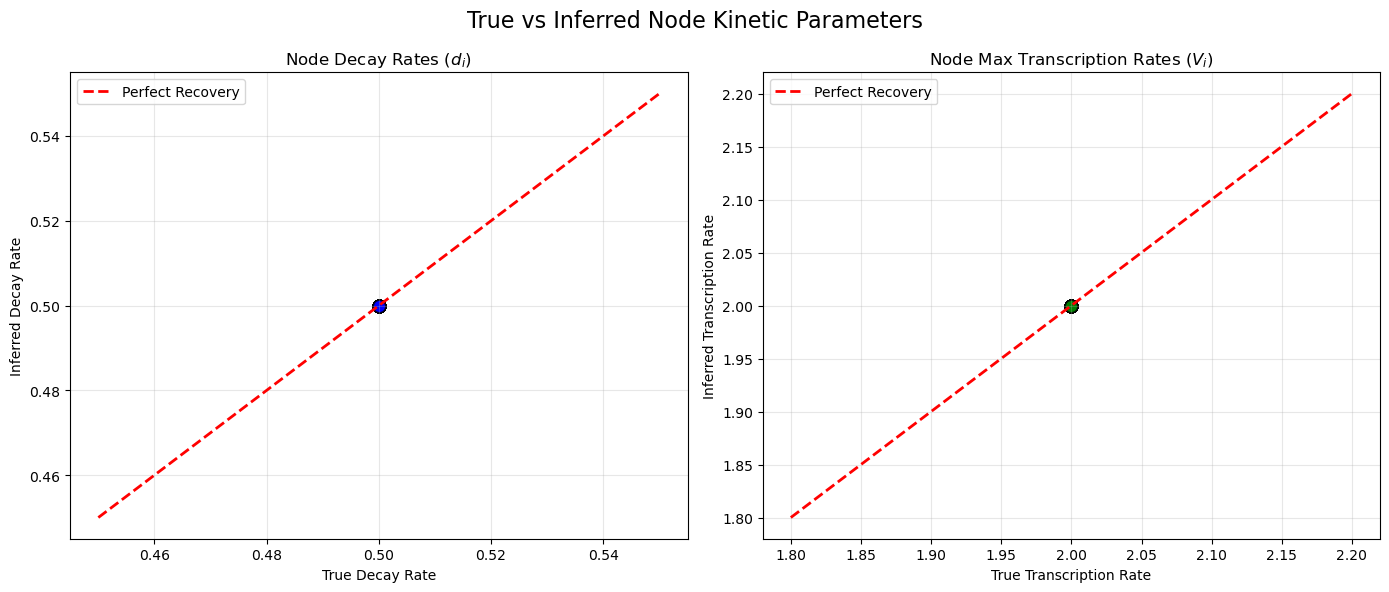

In [29]:
# Extract the inferred parameters from the final MCMC state
# state.theta is a VertexPropertyMap of type vector<double>
# with elements [log(d_i), log(V_i), log(D_base_i)]
theta_array = state.theta.get_2d_array([0, 1])

# In graph-tool, sometimes the parameters are grouped/tied, but we can plot the per-node values
d_inferred = np.exp(theta_array[0, :])
V_inferred = np.exp(theta_array[1, :])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Decay Rate (d)
axes[0].scatter(d_true, d_inferred, color='blue', alpha=0.7, edgecolors='k', s=80)
# Add y=x reference line
min_d, max_d = min(d_true.min(), d_inferred.min()), max(d_true.max(), d_inferred.max())
axes[0].plot([min_d*0.9, max_d*1.1], [min_d*0.9, max_d*1.1], 'r--', lw=2, label="Perfect Recovery")
axes[0].set_title("Node Decay Rates ($d_i$)")
axes[0].set_xlabel("True Decay Rate")
axes[0].set_ylabel("Inferred Decay Rate")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot Transcription Rate (V)
axes[1].scatter(V_true, V_inferred, color='green', alpha=0.7, edgecolors='k', s=80)
# Add y=x reference line
min_V, max_V = min(V_true.min(), V_inferred.min()), max(V_true.max(), V_inferred.max())
axes[1].plot([min_V*0.9, max_V*1.1], [min_V*0.9, max_V*1.1], 'r--', lw=2, label="Perfect Recovery")
axes[1].set_title("Node Max Transcription Rates ($V_i$)")
axes[1].set_xlabel("True Transcription Rate")
axes[1].set_ylabel("Inferred Transcription Rate")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("True vs Inferred Node Kinetic Parameters", fontsize=16)
plt.tight_layout()
plt.show()
